# **Early Warning and Case Forecasting for Zika Virus Outbreaks Across the Americas**

# **Part 1 - Business Problem**

# Business Problem

## Context

The Zika virus epidemic of 2015-2016 spread quickly across Latin America and the Caribbean. It was linked to severe complications such as microcephaly in newborns and Guillain-Barré syndrome. Health agencies reported cases at different geographic levels (country, state, municipality) and at different times, in inconsistent formats. This made it hard to see where the outbreak was growing and where to send resources first.

## Business Problem

A public health agency needs to anticipate where and when Zika cases will rise, so it can allocate limited resources (testing kits, vector control teams, hospital capacity, prenatal screening) before the outbreak peaks.

Today, decisions rely on delayed, heterogeneous reports. There is no consolidated view of how the epidemic evolves by location and indicator, and no forecast to support proactive planning.

## Objectives

1. Consolidate and standardize the epidemiological reports by location, indicator and reporting period.
2. Analyze the temporal and geographic evolution of the outbreak and identify the most affected regions.
3. Forecast the number of reported cases per location for the next reporting periods.
4. Rank locations by risk level to prioritize intervention.

## Key Questions

- Which locations had the fastest growth in reported cases?
- How do confirmed, suspected and complication-related indicators (e.g., microcephaly, GBS) behave over time?
- Is there a lag between case growth and complication reports that can serve as an early signal?
- Can we forecast cases per location with acceptable error?

## Stakeholders

Ministries of health, regional epidemiology teams, hospital networks and international health organizations.

## Success Metrics

- **Forecasting:** MAE, RMSE and MAPE against a hold-out period of the most recent weeks.
- **Risk ranking:** share of the truly highest-growth locations captured in the top-N ranked.
- **Business impact:** how many weeks of lead time the early-warning signal gives over the actual peak.

## Scope and Data

The dataset (CDC Zika Virus Epidemic, Kaggle) contains one row per reported indicator, with these columns:

| Column | Description |
|---|---|
| `report_date` | Date the report was published |
| `location` | Country, state or municipality name |
| `location_type` | Geographic level of the location |
| `data_field` | Indicator being reported (e.g., confirmed cases, microcephaly cases) |
| `data_field_code` | Standardized code for the indicator |
| `time_period` | Reference period of the measurement |
| `time_period_type` | Type of period (e.g., week, month) |
| `value` | Reported numeric value |
| `unit` | Unit of the value (e.g., cases) |

## Deliverables

- Exploratory data analysis of the outbreak by location and indicator.
- A forecasting model for reported cases per location.
- A risk ranking of locations.
- A dashboard or report with recommendations for resource allocation.



In [1]:
"""
Zika Virus Epidemic: dataset download via Kaggle API.
"""

# install kaggle client
!pip install -q kaggle

In [2]:
import os
import shutil
import glob
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


# show all columns without truncation
pd.set_option("display.max_columns", None)

COLOR_PRIMARY = "#0072B2"
COLOR_SECONDARY = "#94A3B8"
COLOR_HIGHLIGHT = "#E69F00"
PALETTE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]

# global chart style
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})

# **Part 2 - API Kaggle**

In [3]:
# read token from colab secrets
#os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_api")

# check token was loaded without printing it
#print("token loaded:", bool(os.environ.get("KAGGLE_API_TOKEN")))

In [4]:
# download and unzip dataset
#!kaggle datasets download -d cdc/zika-virus-epidemic -p /content/data --unzip

# list downloaded files
#!ls -lh /content/data

# Part 3 - Database

In [5]:
# find csv files
csv_files = glob.glob(r"/kaggle/input/datasets/cdc/zika-virus-epidemic/cdc_zika.csv")
print(csv_files)

['/kaggle/input/datasets/cdc/zika-virus-epidemic/cdc_zika.csv']


In [6]:
# load dataset
df = pd.read_csv(csv_files[0], low_memory=False)
df

,report_date,location,location_type,data_field,data_field_code,time_period,time_period_type,value,unit
0,2016-03-19,Argentina-Buenos_Aires,province,cumulative_confirmed_local_cases,AR0001,NaN,NaN,0,cases
1,2016-03-19,Argentina-Buenos_Aires,province,cumulative_probable_local_cases,AR0002,NaN,NaN,0,cases
2,2016-03-19,Argentina-Buenos_Aires,province,cumulative_confirmed_imported_cases,AR0003,NaN,NaN,2,cases
3,2016-03-19,Argentina-Buenos_Aires,province,cumulative_probable_imported_cases,AR0004,NaN,NaN,1,cases
4,2016-03-19,Argentina-Buenos_Aires,province,cumulative_cases_under_study,AR0005,NaN,NaN,127,cases
...,...,...,...,...,...,...,...,...,...
107614,2016-06-28,United_States_Virgin_Islands,territory,confirmed_conjunctivitis,VI0017,NaN,NaN,7,cases
107615,2016-06-28,United_States_Virgin_Islands,territory,confirmed_eyepain,VI0018,NaN,NaN,13,cases
107616,2016-06-28,United_States_Virgin_Islands,territory,confirmed_headache,VI0019,NaN,NaN,14,cases
107617,2016-06-28,United_States_Virgin_Islands,territory,confirmed_malaise,VI0020,NaN,NaN,5,cases


In [7]:
df.head()

,report_date,location,location_type,data_field,data_field_code,time_period,time_period_type,value,unit
0,2016-03-19,Argentina-Buenos_Aires,province,cumulative_confirmed_local_cases,AR0001,NaN,NaN,0,cases
1,2016-03-19,Argentina-Buenos_Aires,province,cumulative_probable_local_cases,AR0002,NaN,NaN,0,cases
2,2016-03-19,Argentina-Buenos_Aires,province,cumulative_confirmed_imported_cases,AR0003,NaN,NaN,2,cases
3,2016-03-19,Argentina-Buenos_Aires,province,cumulative_probable_imported_cases,AR0004,NaN,NaN,1,cases
4,2016-03-19,Argentina-Buenos_Aires,province,cumulative_cases_under_study,AR0005,NaN,NaN,127,cases


In [8]:
df.tail()

,report_date,location,location_type,data_field,data_field_code,time_period,time_period_type,value,unit
107614,2016-06-28,United_States_Virgin_Islands,territory,confirmed_conjunctivitis,VI0017,NaN,NaN,7,cases
107615,2016-06-28,United_States_Virgin_Islands,territory,confirmed_eyepain,VI0018,NaN,NaN,13,cases
107616,2016-06-28,United_States_Virgin_Islands,territory,confirmed_headache,VI0019,NaN,NaN,14,cases
107617,2016-06-28,United_States_Virgin_Islands,territory,confirmed_malaise,VI0020,NaN,NaN,5,cases
107618,2016-06-28,United_States_Virgin_Islands,territory,zika_no_specimen,VI0021,NaN,NaN,2,cases


In [9]:
# first look at the data
df.shape

(107619, 9)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107619 entries, 0 to 107618
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   report_date       107612 non-null  object 
 1   location          107612 non-null  object 
 2   location_type     107612 non-null  object 
 3   data_field        107612 non-null  object 
 4   data_field_code   107612 non-null  object 
 5   time_period       0 non-null       float64
 6   time_period_type  0 non-null       float64
 7   value             107481 non-null  object 
 8   unit              107612 non-null  object 
dtypes: float64(2), object(7)
memory usage: 7.4+ MB


In [11]:
df.dtypes

report_date          object
location             object
location_type        object
data_field           object
data_field_code      object
time_period         float64
time_period_type    float64
value                object
unit                 object
dtype: object

In [12]:
# missing values per column
df.isna().sum()

report_date              7
location                 7
location_type            7
data_field               7
data_field_code          7
time_period         107619
time_period_type    107619
value                  138
unit                     7
dtype: int64

In [13]:
# unique values of key categorical columns
for col in ["location_type", "data_field", "time_period_type", "unit"]:
    print(col, df[col].nunique())
    print(df[col].value_counts().head(15))
    print()

location_type 11
location_type
municipality    87557
state            8462
province         7583
county           1613
country           866
territory         777
department        600
Department         95
region             35
city               14
district           10
Name: count, dtype: int64

data_field 148
data_field
zika_confirmed_laboratory              28963
zika_suspected                         28963
zika_suspected_clinic                  16170
zika_confirmed_clinic                  12793
yearly_reported_travel_cases            1035
yearly_cumulative_male                   960
weekly_zika_confirmed                    960
yearly_cumulative_female                 960
zika_reported_local                      709
zika_reported_travel                     709
microcephaly_confirmed                   567
microcephaly_under_investigation         567
microcephaly_not                         567
municipality_microcephaly                553
municipality_microcephaly_suspected      540

# **Part 4 - Time series analysis**

In [14]:
# shape and column types
print(df.shape)
df.dtypes.to_frame("dtype")

(107619, 9)


,dtype
report_date,object
location,object
location_type,object
data_field,object
data_field_code,object
time_period,float64
time_period_type,float64
value,object
unit,object


In [15]:
# reported indicators and their frequency
df["data_field"].value_counts().head(20).to_frame("rows")

,rows
data_field,
zika_confirmed_laboratory,28963
zika_suspected,28963
zika_suspected_clinic,16170
zika_confirmed_clinic,12793
yearly_reported_travel_cases,1035
yearly_cumulative_male,960
weekly_zika_confirmed,960
yearly_cumulative_female,960
zika_reported_local,709


In [16]:
# geographic levels
df["location_type"].value_counts().to_frame("rows")

,rows
location_type,
municipality,87557
state,8462
province,7583
county,1613
country,866
territory,777
department,600
Department,95
region,35


In [17]:
# period type and unit of measurement
df[["time_period_type", "unit"]].value_counts(dropna=False).to_frame("rows")

rows
time_period_type unit                  
NaN              cases           106519
                 municipalities    1093
                 NaN                  7

In [18]:
# convert dates and values
df["report_date"] = pd.to_datetime(df["report_date"], errors="coerce")
df["value"] = pd.to_numeric(df["value"], errors="coerce")
df[["report_date", "value"]].describe(include="all")

,report_date,value
count,107372,107478.000000
mean,2016-04-04 08:14:49.438586880,48.634548
min,2015-11-28 00:00:00,0.000000
25%,2016-02-20 00:00:00,0.000000
50%,2016-04-09 00:00:00,0.000000
75%,2016-05-14 00:00:00,2.000000
max,2016-07-02 00:00:00,161241.000000
std,NaN,1343.204370


In [19]:
# convert types and drop invalid rows
df["report_date"] = pd.to_datetime(df["report_date"], errors="coerce")
df["value"] = pd.to_numeric(df["value"], errors="coerce")
df = df.dropna(subset=["report_date", "value"])
df.shape

(107238, 9)

In [20]:
# choose indicators by keyword
fields = df["data_field"].str.lower()
CASES_FIELD = df.loc[fields.str.contains("confirm"), "data_field"].value_counts().index[0]
COMPLICATIONS_FIELD = df.loc[fields.str.contains("microcephaly|guillain|gbs"), "data_field"].value_counts().index[0]
print(CASES_FIELD, "|", COMPLICATIONS_FIELD)

zika_confirmed_laboratory | microcephaly_confirmed


In [21]:
# one geographic level only, to avoid double counting
LEVEL = df.loc[df["data_field"] == CASES_FIELD, "location_type"].value_counts().index[0]
cases = df[(df["data_field"] == CASES_FIELD) & (df["location_type"] == LEVEL)]
print(LEVEL, cases["location"].nunique(), "locations,", cases.duplicated(["location", "report_date"]).sum(), "duplicated keys")

municipality 1181 locations, 0 duplicated keys


In [22]:
# one geographic level only, to avoid double counting
LEVEL = df.loc[df["data_field"] == CASES_FIELD, "location_type"].value_counts().index[0]
cases = df[(df["data_field"] == CASES_FIELD) & (df["location_type"] == LEVEL)]
print(LEVEL, cases["location"].nunique(), "locations,", cases.duplicated(["location", "report_date"]).sum(), "duplicated keys")

municipality 1181 locations, 0 duplicated keys


In [23]:
# one row per location and date, and new cases per report
cases = cases.groupby(["location", "report_date"], as_index=False)["value"].max().sort_values(["location", "report_date"])
CUMULATIVE = cases.groupby("location")["value"].apply(lambda s: s.is_monotonic_increasing).mean() > 0.8
cases["new_cases"] = cases.groupby("location")["value"].diff().clip(lower=0).fillna(0) if CUMULATIVE else cases["value"]

# same preparation for complications, assuming same behavior
complications = df[df["data_field"] == COMPLICATIONS_FIELD]
complications = complications[complications["location_type"] == complications["location_type"].value_counts().index[0]]
complications = complications.groupby(["location", "report_date"], as_index=False)["value"].max().sort_values(["location", "report_date"])
complications["new_cases"] = complications.groupby("location")["value"].diff().clip(lower=0).fillna(0) if CUMULATIVE else complications["value"]
complications.head()

,location,report_date,value,new_cases
0,Brazil-Acre,2016-02-13,0.0,0.0
1,Brazil-Acre,2016-02-20,0.0,0.0
2,Brazil-Acre,2016-02-27,0.0,0.0
3,Brazil-Acre,2016-03-05,0.0,0.0
4,Brazil-Acre,2016-03-12,0.0,0.0


In [24]:
# most frequent indicator and geographic level
INDICATOR = df["data_field"].value_counts().index[0]
LEVEL = df.loc[df["data_field"] == INDICATOR, "location_type"].value_counts().index[0]

base = df[(df["data_field"] == INDICATOR) & (df["location_type"] == LEVEL)]
base = base.dropna(subset=["report_date", "value"])
print(INDICATOR, "|", LEVEL, "|", base.shape, "|", base["location"].nunique(), "locations")

zika_suspected | municipality | (28963, 9) | 1181 locations


In [25]:
# most frequent indicator and geographic level
INDICATOR = df["data_field"].value_counts().index[0]
LEVEL = df.loc[df["data_field"] == INDICATOR, "location_type"].value_counts().index[0]

base = df[(df["data_field"] == INDICATOR) & (df["location_type"] == LEVEL)]
base = base.dropna(subset=["report_date", "value"])
print(INDICATOR, "|", LEVEL, "|", base.shape, "|", base["location"].nunique(), "locations")

zika_suspected | municipality | (28963, 9) | 1181 locations


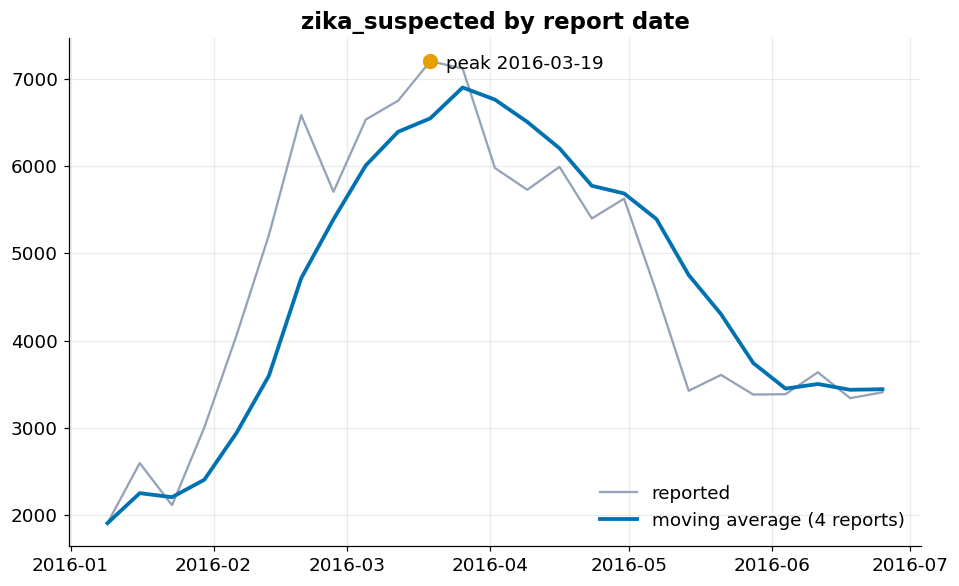

In [26]:
series = base.groupby("report_date")["value"].sum()
peak = series.idxmax()

fig, ax = plt.subplots()
ax.plot(series.index, series.values, color=COLOR_SECONDARY, label="reported")
ax.plot(series.index, series.rolling(4, min_periods=1).mean(), color=COLOR_PRIMARY, lw=2.5, label="moving average (4 reports)")
ax.scatter(peak, series.max(), color=COLOR_HIGHLIGHT, s=80, zorder=5)
ax.annotate(f"peak {peak:%Y-%m-%d}", (peak, series.max()), textcoords="offset points", xytext=(10, -5))
ax.set_title(f"{INDICATOR} by report date")
ax.legend(frameon=False)
plt.show()

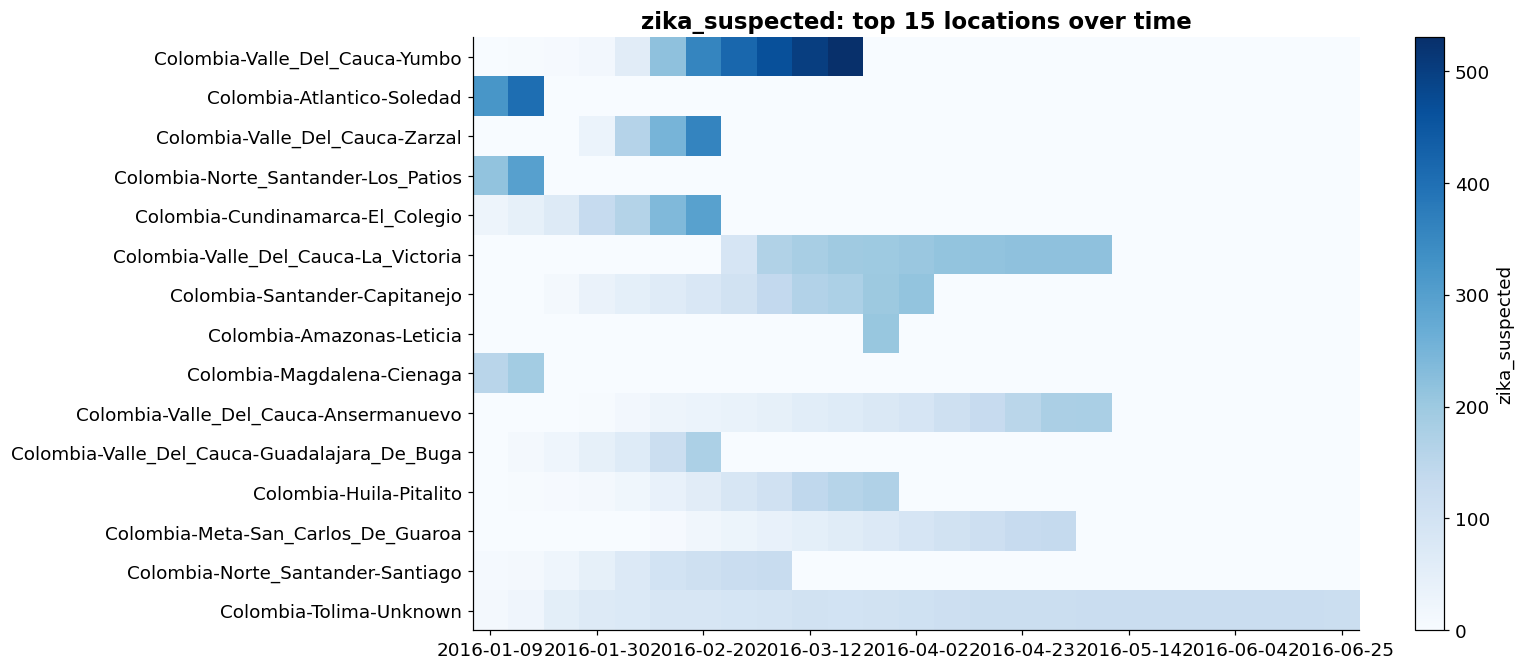

In [27]:
top = base.groupby("location")["value"].max().nlargest(15).index
heatmap_data = base[base["location"].isin(top)].pivot_table(index="location", columns="report_date", values="value", aggfunc="sum").loc[top]

fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(heatmap_data.fillna(0), aspect="auto", cmap="Blues")
ax.set_yticks(range(len(heatmap_data)), heatmap_data.index)
pos = list(range(0, heatmap_data.shape[1], max(1, heatmap_data.shape[1] // 8)))
ax.set_xticks(pos, [f"{heatmap_data.columns[i]:%Y-%m-%d}" for i in pos])
ax.grid(False)
fig.colorbar(im, label=INDICATOR)
ax.set_title(f"{INDICATOR}: top 15 locations over time")
plt.show()

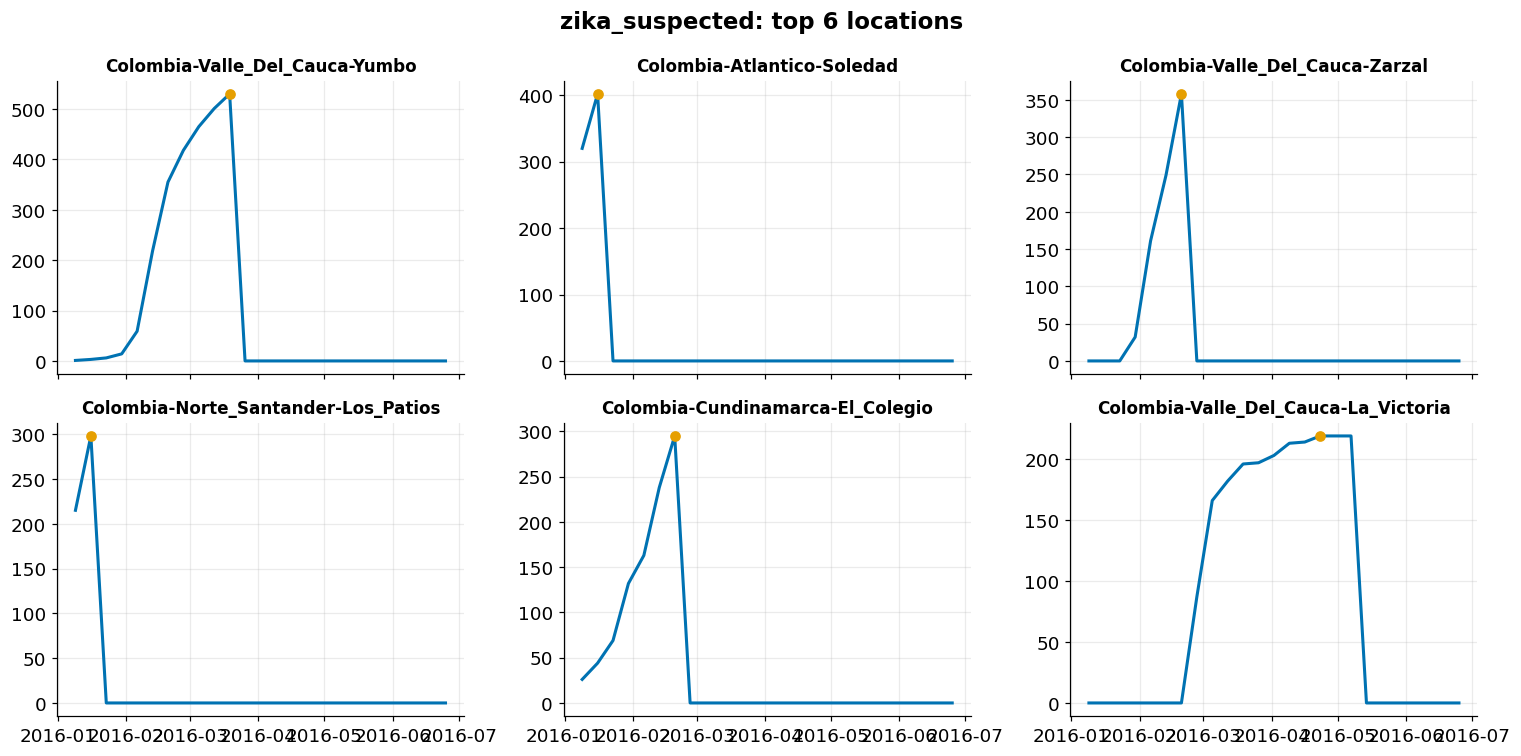

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, loc in zip(axes.ravel(), top[:6]):
    s = base[base["location"] == loc].groupby("report_date")["value"].sum()
    ax.plot(s.index, s.values, color=COLOR_PRIMARY, lw=2)
    ax.scatter(s.idxmax(), s.max(), color=COLOR_HIGHLIGHT, zorder=5)
    ax.set_title(loc, fontsize=11)
fig.suptitle(f"{INDICATOR}: top 6 locations", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

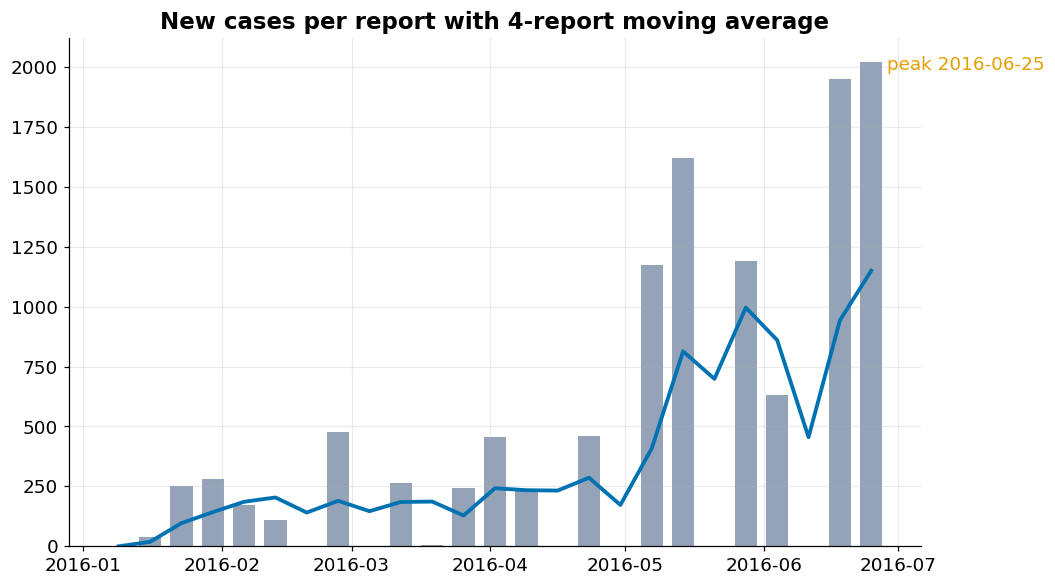

In [29]:
tot = cases.groupby("report_date")["new_cases"].sum()
peak = tot.idxmax()
fig, ax = plt.subplots()
ax.bar(tot.index, tot.values, width=5, color=COLOR_SECONDARY)
ax.plot(tot.index, tot.rolling(4, min_periods=1).mean(), color=COLOR_PRIMARY, lw=2.5)
ax.annotate(f"peak {peak:%Y-%m-%d}", (peak, tot.max()), xytext=(10, -5), textcoords="offset points", color=COLOR_HIGHLIGHT)
ax.set_title("New cases per report with 4-report moving average")
plt.show()

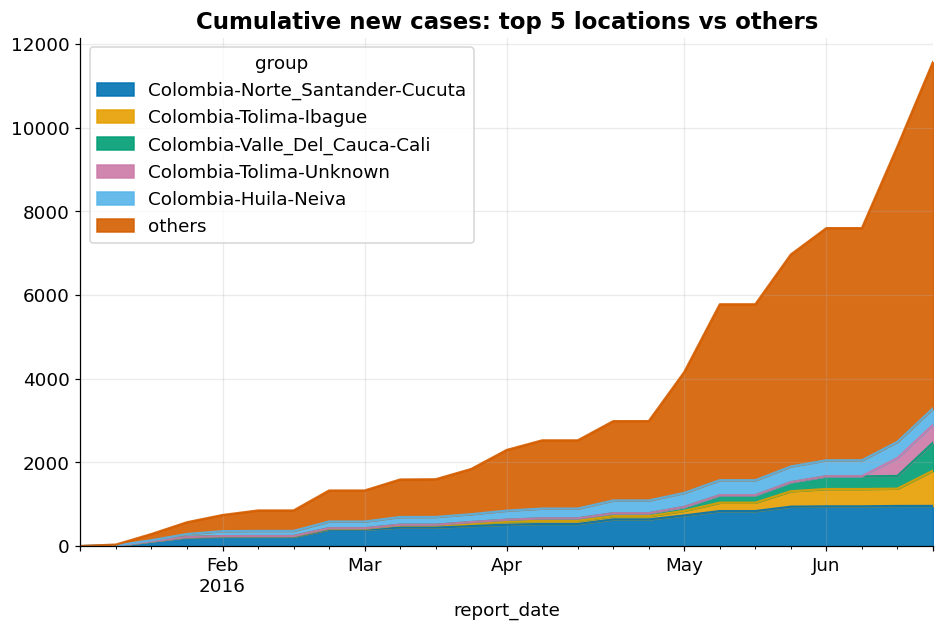

In [30]:
top5 = cases.groupby("location")["new_cases"].sum().nlargest(5).index
grouped = cases.assign(group=cases["location"].where(cases["location"].isin(top5), "others"))
area = grouped.pivot_table(index="report_date", columns="group", values="new_cases", aggfunc="sum").fillna(0).cumsum()
area = area.reindex(columns=[*top5, "others"]).dropna(axis=1, how="all")
ax = area.plot.area(figsize=(10, 6), color=PALETTE + [COLOR_SECONDARY], alpha=0.9)
ax.set_title("Cumulative new cases: top 5 locations vs others")
plt.show()

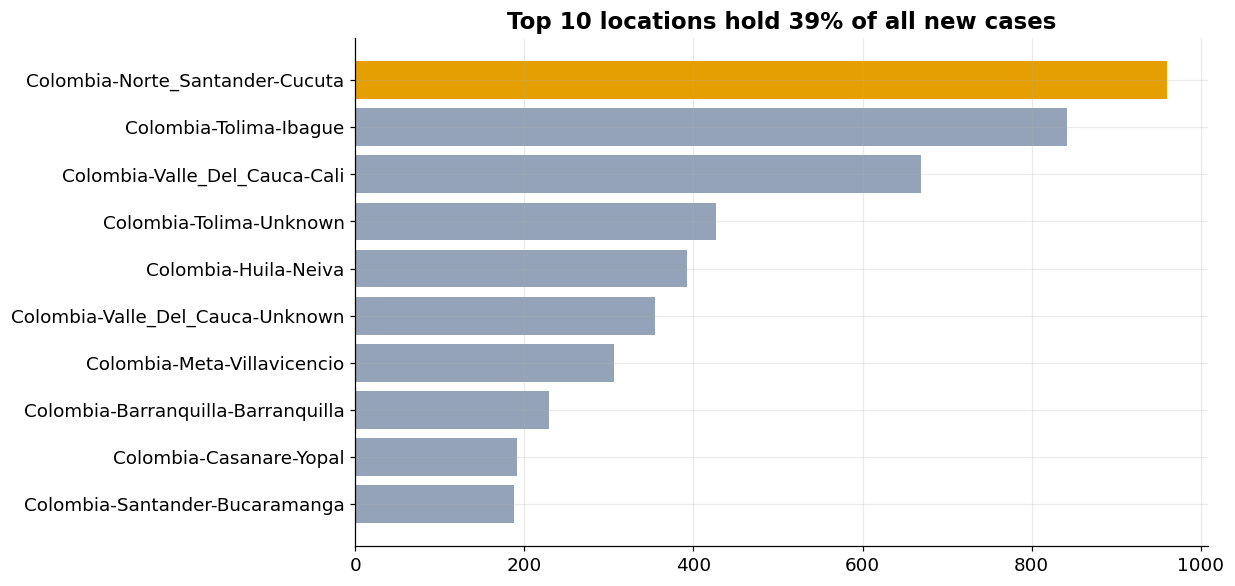

In [31]:
rank = cases.groupby("location")["new_cases"].sum().nlargest(10).sort_values()
fig, ax = plt.subplots()
ax.barh(rank.index, rank.values, color=COLOR_SECONDARY)
ax.barh(rank.index[-1], rank.values[-1], color=COLOR_HIGHLIGHT)
ax.set_title(f"Top 10 locations hold {rank.sum() / cases['new_cases'].sum():.0%} of all new cases")
plt.show()

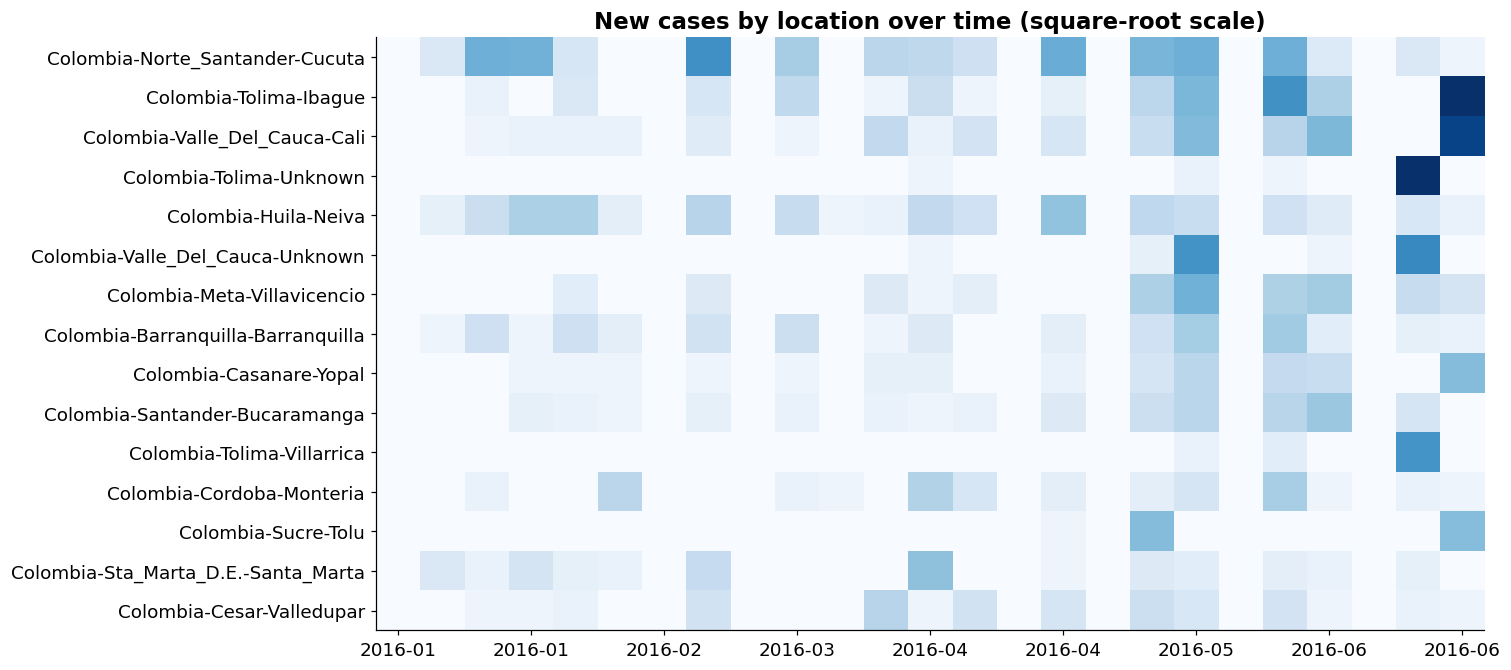

In [32]:
top15 = cases.groupby("location")["new_cases"].sum().nlargest(15).index
heatmap_data = cases[cases["location"].isin(top15)].pivot_table(index="location", columns="report_date", values="new_cases", aggfunc="sum").reindex(top15)
step = max(1, heatmap_data.shape[1] // 8)
fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(heatmap_data.fillna(0) ** 0.5, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(heatmap_data)), heatmap_data.index)
ax.set_xticks(range(0, heatmap_data.shape[1], step), [f"{d:%Y-%m}" for d in heatmap_data.columns[::step]])
ax.grid(False)
ax.set_title("New cases by location over time (square-root scale)")
plt.show()

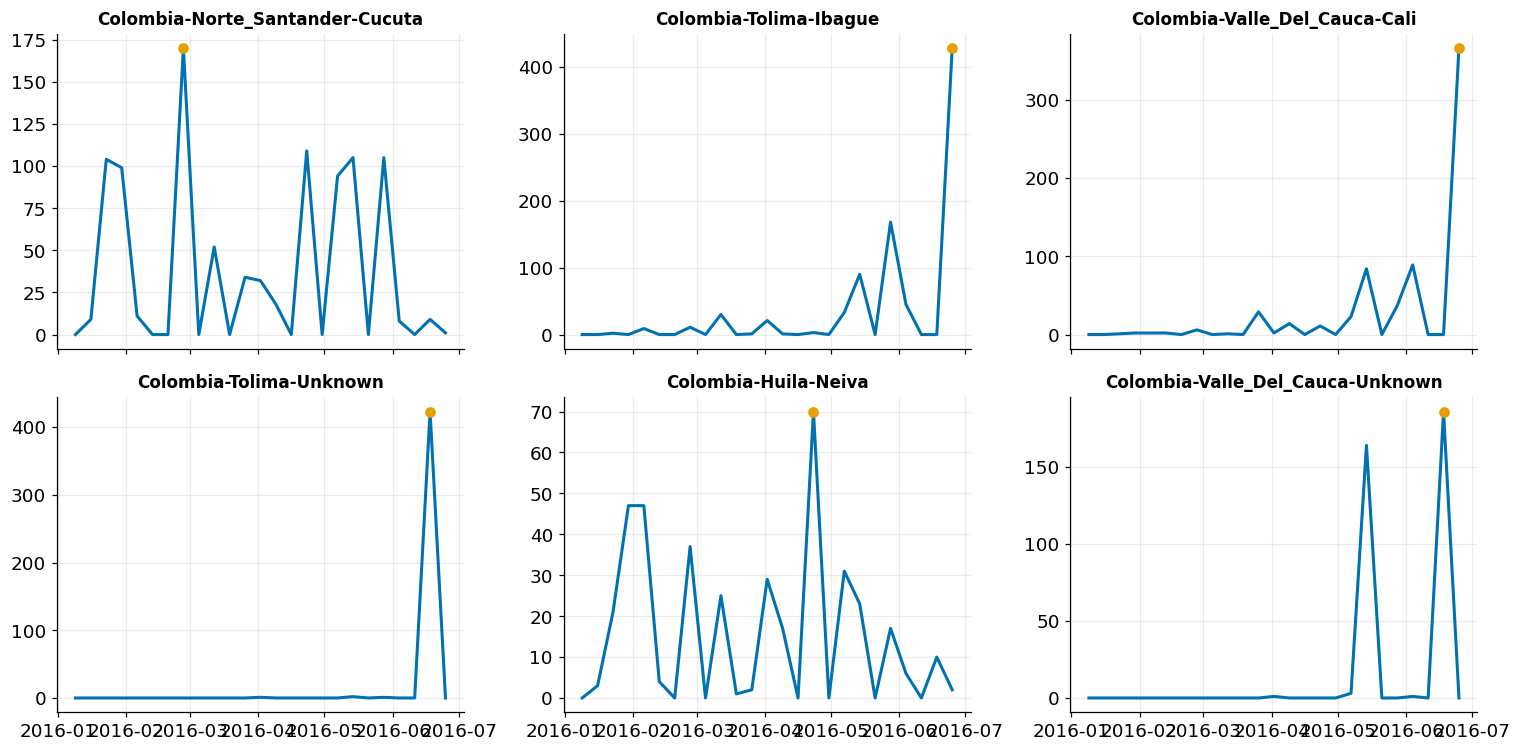

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, loc in zip(axes.ravel(), top15[:6]):
    s = cases[cases["location"] == loc].set_index("report_date")["new_cases"]
    ax.plot(s.index, s.values, color=COLOR_PRIMARY, lw=2)
    ax.scatter(s.idxmax(), s.max(), color=COLOR_HIGHLIGHT, zorder=5)
    ax.set_title(loc, fontsize=11)
plt.tight_layout()
plt.show()

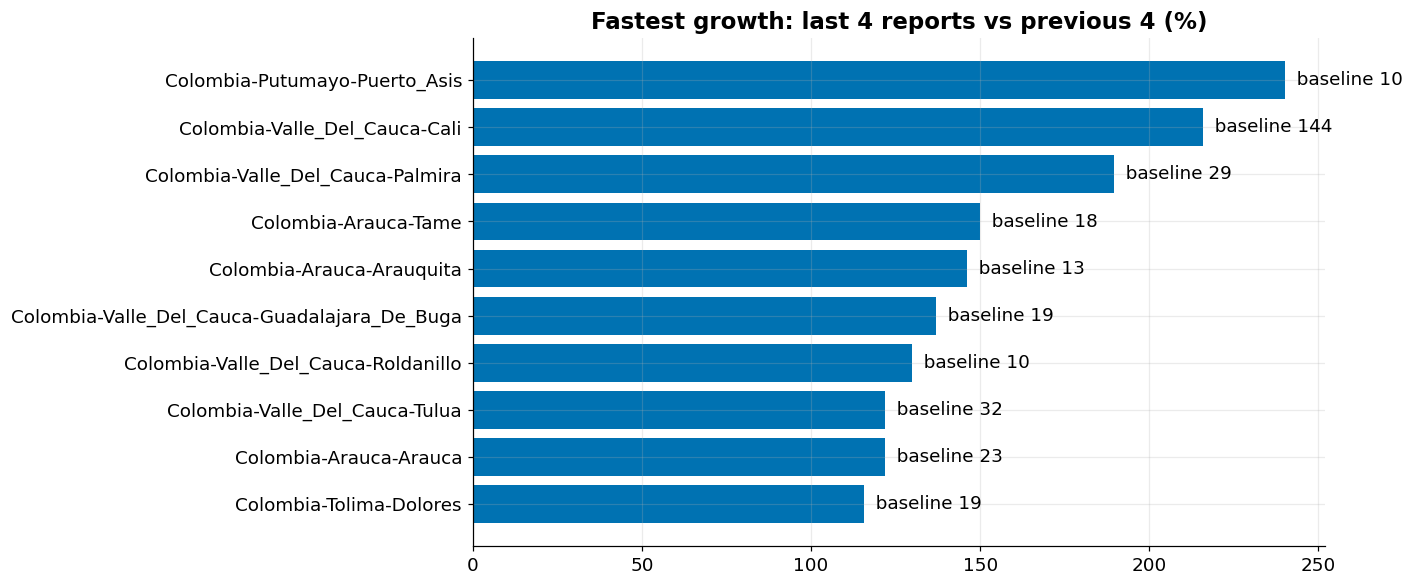

In [34]:
MIN_BASELINE = 10
dates = np.sort(cases["report_date"].unique())
recent = cases[cases["report_date"].isin(dates[-4:])].groupby("location")["new_cases"].sum()
previous = cases[cases["report_date"].isin(dates[-8:-4])].groupby("location")["new_cases"].sum()
growth = pd.DataFrame({"recent": recent, "previous": previous}).dropna()
growth = growth[growth["previous"] >= MIN_BASELINE]
growth["growth_pct"] = (growth["recent"] / growth["previous"] - 1) * 100

top_g = growth.nlargest(10, "growth_pct").sort_values("growth_pct")
fig, ax = plt.subplots()
ax.barh(top_g.index, top_g["growth_pct"], color=COLOR_PRIMARY)
for i, (g, b) in enumerate(zip(top_g["growth_pct"], top_g["previous"])):
    ax.text(g, i, f"  baseline {b:.0f}", va="center")
ax.set_title("Fastest growth: last 4 reports vs previous 4 (%)")
plt.show()

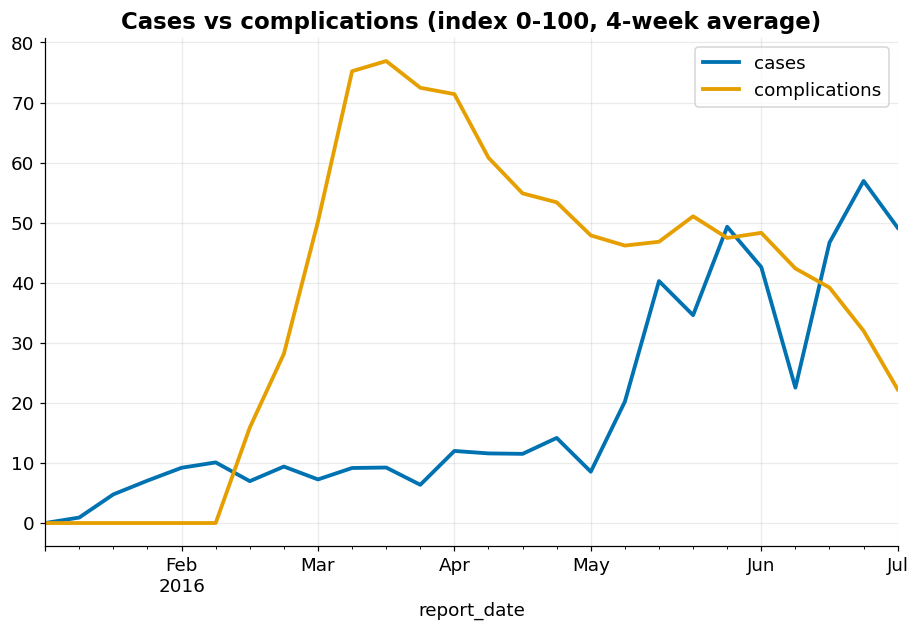

In [35]:
c = cases.groupby("report_date")["new_cases"].sum().resample("W").sum()
m = complications.groupby("report_date")["new_cases"].sum().resample("W").sum()
idx = pd.concat([c.rename("cases"), m.rename("complications")], axis=1).fillna(0)
smoothed = (idx / idx.max() * 100).rolling(4, min_periods=1).mean()
ax = smoothed.plot(figsize=(10, 6), color=[COLOR_PRIMARY, COLOR_HIGHLIGHT], lw=2.5)
ax.set_title("Cases vs complications (index 0-100, 4-week average)")
plt.show()

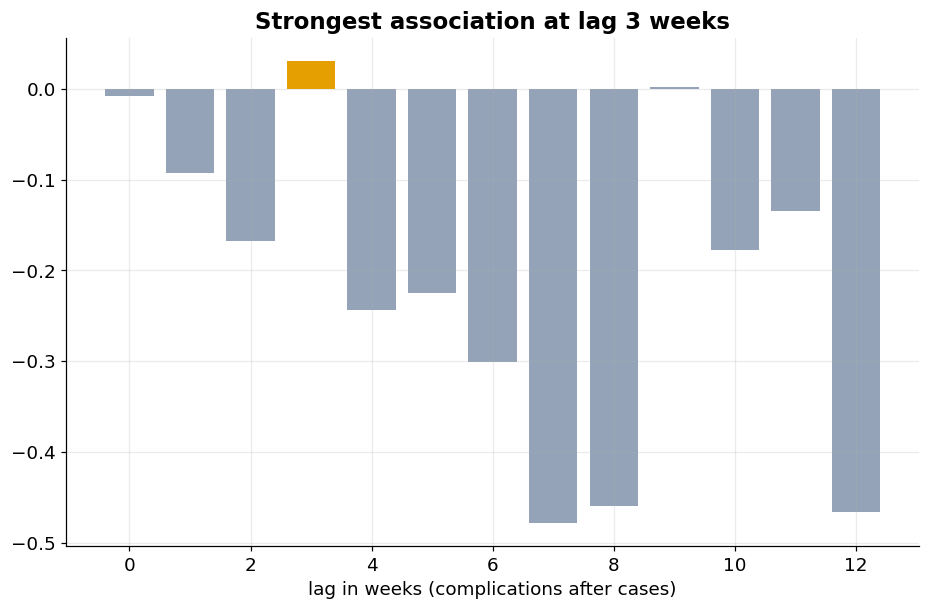

In [36]:
corr = pd.Series({k: idx["cases"].corr(idx["complications"].shift(-k)) for k in range(13)})
fig, ax = plt.subplots()
ax.bar(corr.index, corr.values, color=COLOR_SECONDARY)
ax.bar(corr.idxmax(), corr.max(), color=COLOR_HIGHLIGHT)
ax.set_xlabel("lag in weeks (complications after cases)")
ax.set_title(f"Strongest association at lag {corr.idxmax()} weeks")
plt.show()

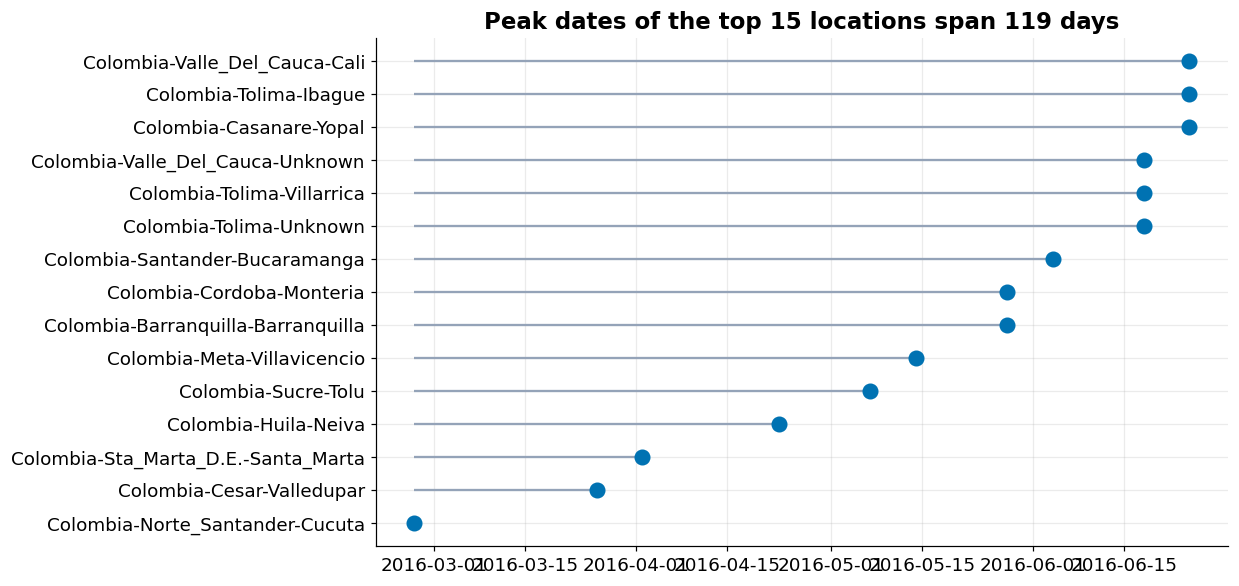

In [37]:
mask = cases["location"].isin(top15)
pos = cases[mask].groupby("location")["new_cases"].idxmax()
pk = cases.loc[pos].set_index("location")["report_date"].sort_values()
fig, ax = plt.subplots()
ax.hlines(pk.index, pk.min(), pk.values, color=COLOR_SECONDARY)
ax.scatter(pk.values, pk.index, color=COLOR_PRIMARY, s=90, zorder=5)
ax.set_title(f"Peak dates of the top 15 locations span {(pk.max() - pk.min()).days} days")
plt.show()

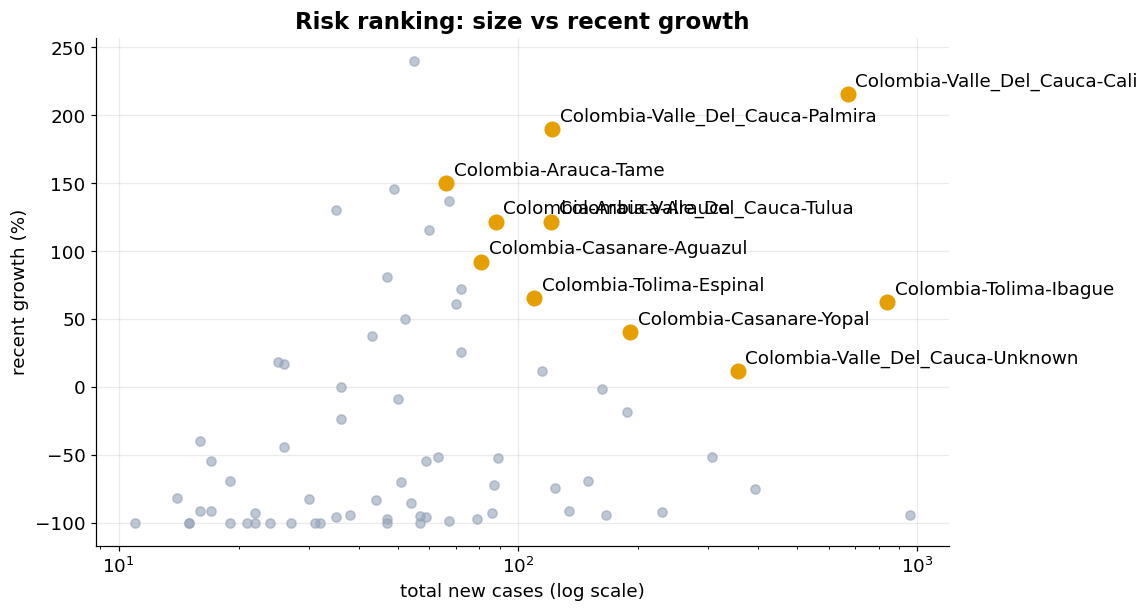

In [38]:
risk = growth.join(cases.groupby("location")["new_cases"].sum().rename("total"))
risk["score"] = risk["growth_pct"].rank(pct=True) * 0.5 + risk["total"].rank(pct=True) * 0.5
top_r = risk.nlargest(10, "score")
top_r.round(1)

fig, ax = plt.subplots()
ax.scatter(risk["total"], risk["growth_pct"], color=COLOR_SECONDARY, alpha=0.6)
ax.scatter(top_r["total"], top_r["growth_pct"], color=COLOR_HIGHLIGHT, s=90, zorder=5)
for loc, r in top_r.iterrows():
    ax.annotate(loc, (r["total"], r["growth_pct"]), xytext=(5, 5), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("total new cases (log scale)")
ax.set_ylabel("recent growth (%)")
ax.set_title("Risk ranking: size vs recent growth")
plt.show()

# Part 5 - Time series analysis Brazil

In [39]:
## How does Brazil appear in the dataset, and what data exists for it?
# Let's filter everything that mentions Brazil and look at the geographic levels, the indicators and the period covered.

# keep every location that mentions brazil
brazil = df[df["location"].str.contains("brazil", case=False, na=False)].copy()
print(brazil.shape, "of", df.shape)
brazil["location_type"].value_counts().to_frame("rows")

(4132, 9) of (107238, 9)


,rows
location_type,
state,4132


In [40]:
# sample of location names
brazil["location"].drop_duplicates().head(15).to_frame("location")

,location
2016,Brazil-Acre
2017,Brazil-Alagoas
2020,Brazil-Bahia
2021,Brazil-Ceara
2022,Brazil-Distrito_Federal
2023,Brazil-Espirito_Santo
2024,Brazil-Goias
2025,Brazil-Maranhao
2026,Brazil-Mato_Grosso
2027,Brazil-Mato_Grosso_do_Sul


In [41]:
# indicators available for brazil
brazil["data_field"].value_counts().to_frame("rows")

,rows
data_field,
microcephaly_confirmed,558
microcephaly_not,558
microcephaly_under_investigation,556
municipality_microcephaly_suspected,523
municipality_microcephaly,482
microcephaly_fatal_under_investigation,420
microcephaly_fatal_confirmed,420
microcephaly_fatal_not,419
zika_reported,196


In [42]:
# date range of reports and period types
print(pd.to_datetime(brazil["report_date"], errors="coerce").agg(["min", "max"]).tolist())
brazil["time_period_type"].value_counts(dropna=False).to_frame("rows")

[Timestamp('2016-02-13 00:00:00'), Timestamp('2016-07-02 00:00:00')]


,rows
time_period_type,
NaN,4132


**Result:** Brazil has 4,132 rows (about 4% of the dataset), all at the state
level. There is no whole-country row, so there is no risk of counting the same
case twice when summing the states. Almost all of the data is about microcephaly,
which is the complication, and not about Zika cases. The case indicator
(`zika_reported`) has only 196 rows. The period runs from February to July 2016,
about 20 weeks. This limits what can be concluded, especially about forecasting
and about the lag between cases and complications.

In [43]:
# ## What does each indicator measure, and how often was it reported?
# Let's look at the unit of each indicator, how many states and dates it covers, and whether the values only go up (cumulative).

# convert types
brazil["report_date"] = pd.to_datetime(brazil["report_date"], errors="coerce")
brazil["value"] = pd.to_numeric(brazil["value"], errors="coerce")

# coverage and unit per indicator
brazil.groupby("data_field").agg(
    unit=("unit", lambda s: ", ".join(s.dropna().unique())),
    states=("location", "nunique"),
    dates=("report_date", "nunique"),
    total=("value", "sum"),
)

,unit,states,dates,total
data_field,,,,
microcephaly_confirmed,cases,27,21,24653.0
microcephaly_fatal_confirmed,cases,26,20,1110.0
microcephaly_fatal_not,cases,26,20,633.0
microcephaly_fatal_under_investigation,cases,26,20,3040.0
microcephaly_not,cases,27,21,47771.0
microcephaly_under_investigation,cases,27,21,76365.0
municipality_microcephaly,municipalities,27,21,9909.0
municipality_microcephaly_suspected,municipalities,27,20,26190.0
zika_reported,cases,28,7,1851464.0


In [44]:
# repeated keys and share of series that never decrease
print("duplicated keys:", brazil.duplicated(["location", "data_field", "report_date"]).sum())
non_decreasing = brazil.sort_values("report_date").groupby(["data_field", "location"])["value"].apply(lambda s: s.is_monotonic_increasing)
non_decreasing.groupby("data_field").mean().round(2).to_frame("never_decreases")

duplicated keys: 0


,never_decreases
data_field,
microcephaly_confirmed,0.74
microcephaly_fatal_confirmed,0.81
microcephaly_fatal_not,0.88
microcephaly_fatal_under_investigation,0.42
microcephaly_not,0.63
microcephaly_under_investigation,0.00
municipality_microcephaly,0.11
municipality_microcephaly_suspected,0.78
zika_reported,0.71


**Result:** the microcephaly indicators do not all measure the same thing. Three
of them (confirmed, discarded and under investigation) count cases and make up the
classification of each notification. The two `municipality_*` indicators count
municipalities, not people, and cannot be added to the cases. The `total` column
in the table above is not a real total: it sums all the reports of the same state,
and when the value is cumulative this counts the same case several times. The
correct number is the one from the latest report. `zika_reported`, for example,
does not have 1.85 million cases by that calculation.

What the second table changed in the plan:

- **The “cases under investigation” are not cumulative. No state series only goes up (0%). This indicator works like a balance: it drops when a case is confirmed or discarded and rises with new notifications. Taking the difference between reports (the idea of “new cases”) gives a wrong number here, so I use the value of each report as a snapshot of the situation on that date.**

- **Confirmed and discarded are almost cumulative. About 74% and 63% of the state series never decrease, but the rest have downward revisions, which are data corrections. Treating everything as cumulative would require cleaning those corrections, and it is not worth it here.**

- **Reported Zika has only 7 dates, versus 21 for microcephaly, and appears in 28 locations (27 states plus one). It serves as national context, not as a time series.**

This changes the 10 charts: “new cases per report” is dropped. The question becomes how the classification of microcephaly cases evolved and which states concentrate the cases under investigation, which is where the agency still has something to decide.

How did the classification of microcephaly cases evolve in Brazil?

How many cases are confirmed, discarded or still under investigation at each report.
Before summing the states, let's check whether all of them reported on every date.

In [45]:
# microcephaly status indicators and states reporting per date
STATUS = ["microcephaly_confirmed", "microcephaly_not", "microcephaly_under_investigation"]
micro = brazil[brazil["data_field"].isin(STATUS)]
coverage = micro.groupby("report_date")["location"].nunique()
coverage.to_frame("states")

,states
report_date,
2016-02-13,25
2016-02-20,25
2016-02-27,26
2016-03-05,26
2016-03-12,26
2016-03-19,26
2016-03-26,26
2016-04-02,27
2016-04-09,27


In [46]:
# extra location in zika_reported
set(brazil.loc[brazil["data_field"] == "zika_reported", "location"]) - set(micro["location"])

{'Brazil'}

In [47]:
# keep dates with at least 90% of states reporting
valid_dates = coverage[coverage >= coverage.max() * 0.9].index
status = micro[micro["report_date"].isin(valid_dates)].pivot_table(index="report_date", columns="data_field", values="value", aggfunc="sum")[STATUS]
print(len(coverage) - len(valid_dates), "dates dropped for low coverage")
status.tail()

0 dates dropped for low coverage


data_field,microcephaly_confirmed,microcephaly_not,microcephaly_under_investigation
report_date,,,
2016-06-04,1551.0,3262.0,3017.0
2016-06-11,1581.0,3308.0,3047.0
2016-06-18,1616.0,3416.0,3007.0
2016-06-25,1638.0,3466.0,3061.0
2016-07-02,1656.0,3515.0,3130.0


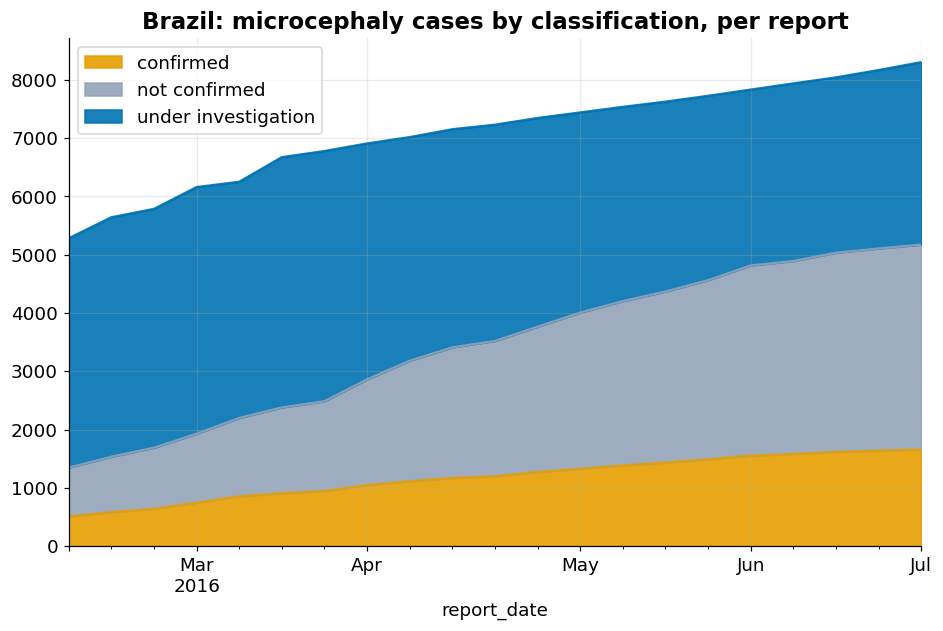

In [48]:
status.columns = ["confirmed", "not confirmed", "under investigation"]
ax = status.plot.area(figsize=(10, 6), color=[COLOR_HIGHLIGHT, COLOR_SECONDARY, COLOR_PRIMARY], alpha=0.9)
ax.set_title("Brazil: microcephaly cases by classification, per report")
plt.show()

**Result:** the total number of microcephaly notifications in Brazil rose from about 5,300 to 8,300 between February and July 2016, but what changed was the classification. The "under investigation" queue went from about 3 in every 4 cases to a little over 1 in every 3 (3,130 of 8,301 in the latest report).

Discarded cases grew more than confirmed ones: in the latest report there are 3,515 discarded versus 1,656 confirmed, meaning about 68% of the cases already resolved were discarded. The pace of confirmation slowed in June (+105 confirmed in four reports).

Which states concentrate the cases still under investigation?
Ranking by the number of pending cases in the latest report, with the share
this represents of each state's notifications, to separate large states
from states with a backlogged queue.

In [49]:
# latest report per state
latest_date = micro["report_date"].max()
states = micro[micro["report_date"] == latest_date].pivot_table(index="location", columns="data_field", values="value", aggfunc="sum")[STATUS]
states.columns = ["confirmed", "not confirmed", "under investigation"]
states.index = states.index.str.replace("Brazil-", "", regex=False)
states["total"] = states.sum(axis=1)
states["pending_share"] = states["under investigation"] / states["total"]
states.nlargest(10, "under investigation")

,confirmed,not confirmed,under investigation,total,pending_share
location,,,,,
Bahia,265.0,251.0,659.0,1175.0,0.560851
Pernambuco,367.0,1173.0,489.0,2029.0,0.241005
Sao_Paulo,10.0,179.0,290.0,479.0,0.605428
Rio_de_Janeiro,83.0,168.0,286.0,537.0,0.532588
Paraiba,148.0,479.0,262.0,889.0,0.294713
Rio_Grande_do_Norte,113.0,66.0,261.0,440.0,0.593182
Ceara,125.0,221.0,175.0,521.0,0.335893
Maranhao,131.0,62.0,89.0,282.0,0.315603
Mato_Grosso,31.0,120.0,89.0,240.0,0.370833


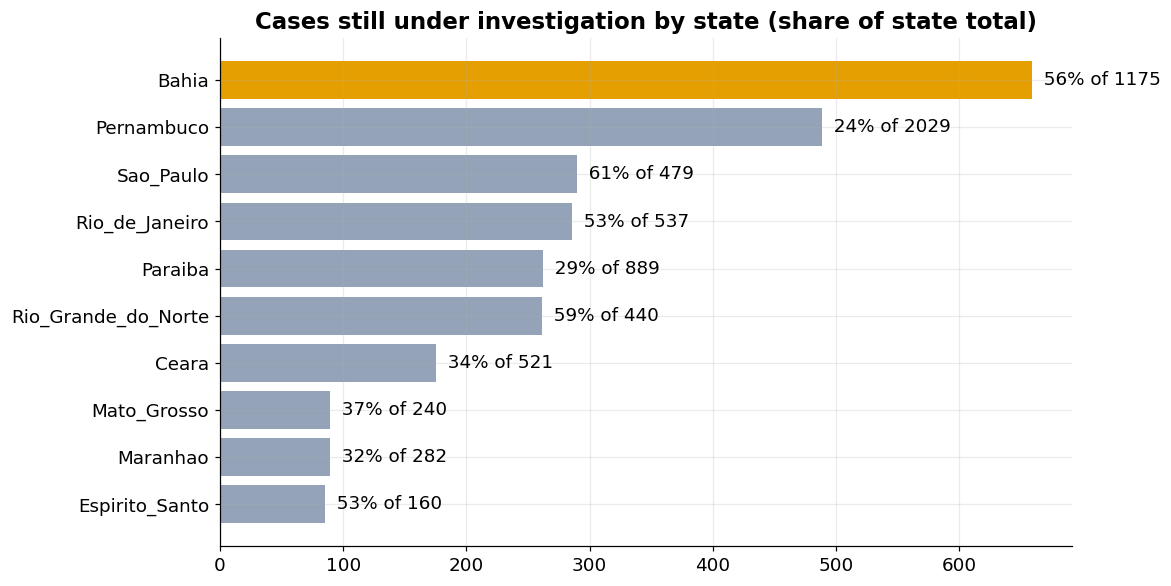

In [50]:
# top 10 states by pending cases, labeled with share and total
top = states.nlargest(10, "under investigation").sort_values("under investigation")
fig, ax = plt.subplots()
ax.barh(top.index, top["under investigation"], color=COLOR_SECONDARY)
ax.barh(top.index[-1], top["under investigation"].iloc[-1], color=COLOR_HIGHLIGHT)
for i, (v, s, n) in enumerate(zip(top["under investigation"], top["pending_share"], top["total"])):
    ax.text(v, i, f"  {s:.0%} of {n:.0f}", va="center")
ax.set_title("Cases still under investigation by state (share of state total)")
plt.show()

**Result:** the investigation queue is concentrated. The 10 states in the chart
add up to 2,685 of the 3,130 pending cases (86%), and Bahia, Pernambuco and São
Paulo alone account for 46%. Bahia is the only state that combines a large queue
(659 cases, 56% of its notifications) with many confirmed cases (265), which
makes it the clearest candidate for investigation reinforcement. Pernambuco
has the largest volume (2,029 notifications), but only 24% pending: most of it
has already been resolved, mostly discarded. São Paulo (61%) and Rio Grande do
Norte (59%) have more than half of their notifications still open, but with
opposite profiles among the cases already resolved.

**Is each state's queue shrinking or growing?**

We compare the latest pending cases with those from 8 reports ago (about 2 months). A state with a large queue that is shrinking needs less reinforcement than one with a growing queue.

In [51]:
# pending cases per state, 8 reports ago vs latest
pending = micro[micro["data_field"] == "microcephaly_under_investigation"].pivot_table(index="report_date", columns="location", values="value", aggfunc="sum")
pending.columns = pending.columns.str.replace("Brazil-", "", regex=False)
dates = pending.index.sort_values()
queue = pd.DataFrame({"8 reports ago": pending.loc[dates[-9]], "latest": pending.loc[dates[-1]]})
queue["change"] = queue["latest"] - queue["8 reports ago"]
queue.nlargest(10, "latest")

,8 reports ago,latest,change
location,,,
Bahia,648.0,659.0,11.0
Pernambuco,582.0,489.0,-93.0
Sao_Paulo,163.0,290.0,127.0
Rio_de_Janeiro,295.0,286.0,-9.0
Paraiba,344.0,262.0,-82.0
Rio_Grande_do_Norte,265.0,261.0,-4.0
Ceara,231.0,175.0,-56.0
Maranhao,93.0,89.0,-4.0
Mato_Grosso,121.0,89.0,-32.0


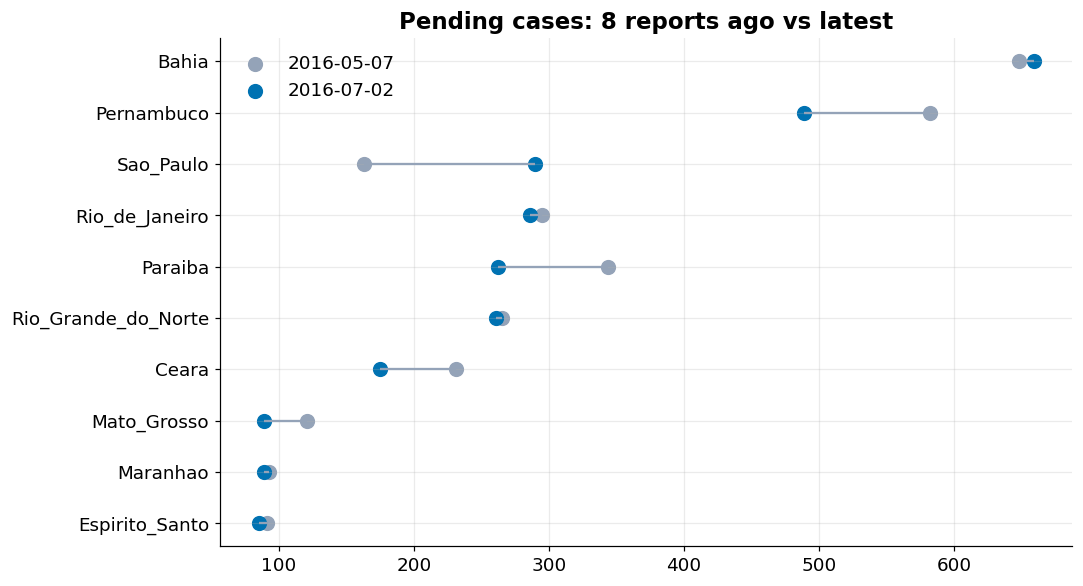

In [52]:
# dumbbell chart: previous vs latest pending
top = queue.nlargest(10, "latest").sort_values("latest")
fig, ax = plt.subplots()
ax.hlines(top.index, top["8 reports ago"], top["latest"], color=COLOR_SECONDARY)
ax.scatter(top["8 reports ago"], top.index, color=COLOR_SECONDARY, s=80, label=f"{dates[-9]:%Y-%m-%d}")
ax.scatter(top["latest"], top.index, color=COLOR_PRIMARY, s=80, label=f"{dates[-1]:%Y-%m-%d}")
ax.legend(frameon=False)
ax.set_title("Pending cases: 8 reports ago vs latest")
plt.show()

**Result:** the queue of the 10 states with the most pending cases shrank only a
little, from 2,833 to 2,685 (-5%) in two months, and the movement is uneven.
Pernambuco, Paraíba, Ceará and Mato Grosso reduced their queues by between 16%
and 26%. Rio de Janeiro, Rio Grande do Norte, Maranhão and Espírito Santo stayed
practically flat (a change of at most 9 cases). Bahia, which has the largest
queue, did not reduce it: it went from 648 to 659. São Paulo is the only state
with a clear worsening, from 163 to 290 cases (+78%). Bahia and São Paulo are,
therefore, the states where the queue is large and is not being reduced.

Did the queue shrink because cases were confirmed or discarded?

For each state, we compare the change in confirmed, discarded and pending cases over the same window. This separates the states that are resolving cases from those that are stalled.

In [53]:
# change per classification between the two dates
d0, d1 = dates[-9], dates[-1]
two_dates = micro[micro["report_date"].isin([d0, d1])].pivot_table(index="location", columns=["report_date", "data_field"], values="value", aggfunc="sum")
delta = (two_dates[d1] - two_dates[d0])[STATUS]
delta.columns = ["confirmed", "not confirmed", "under investigation"]
delta.index = delta.index.str.replace("Brazil-", "", regex=False)
delta["resolved"] = delta["confirmed"] + delta["not confirmed"]
delta.loc[queue.nlargest(10, "latest").index]

,confirmed,not confirmed,under investigation,resolved
location,,,,
Bahia,28.0,62.0,11.0,90.0
Pernambuco,16.0,176.0,-93.0,192.0
Sao_Paulo,2.0,76.0,127.0,78.0
Rio_de_Janeiro,36.0,76.0,-9.0,112.0
Paraiba,29.0,69.0,-82.0,98.0
Rio_Grande_do_Norte,7.0,16.0,-4.0,23.0
Ceara,35.0,64.0,-56.0,99.0
Maranhao,15.0,20.0,-4.0,35.0
Mato_Grosso,16.0,42.0,-32.0,58.0


In [54]:
# states outside the current top 10 with the largest queue reduction
outside_top10 = queue.drop(queue.nlargest(10, "latest").index)
outside_top10.nsmallest(5, "change")

,8 reports ago,latest,change
location,,,
Sergipe,156.0,74.0,-82.0
Tocantins,110.0,59.0,-51.0
Goias,66.0,50.0,-16.0
Alagoas,77.0,67.0,-10.0
Acre,20.0,11.0,-9.0


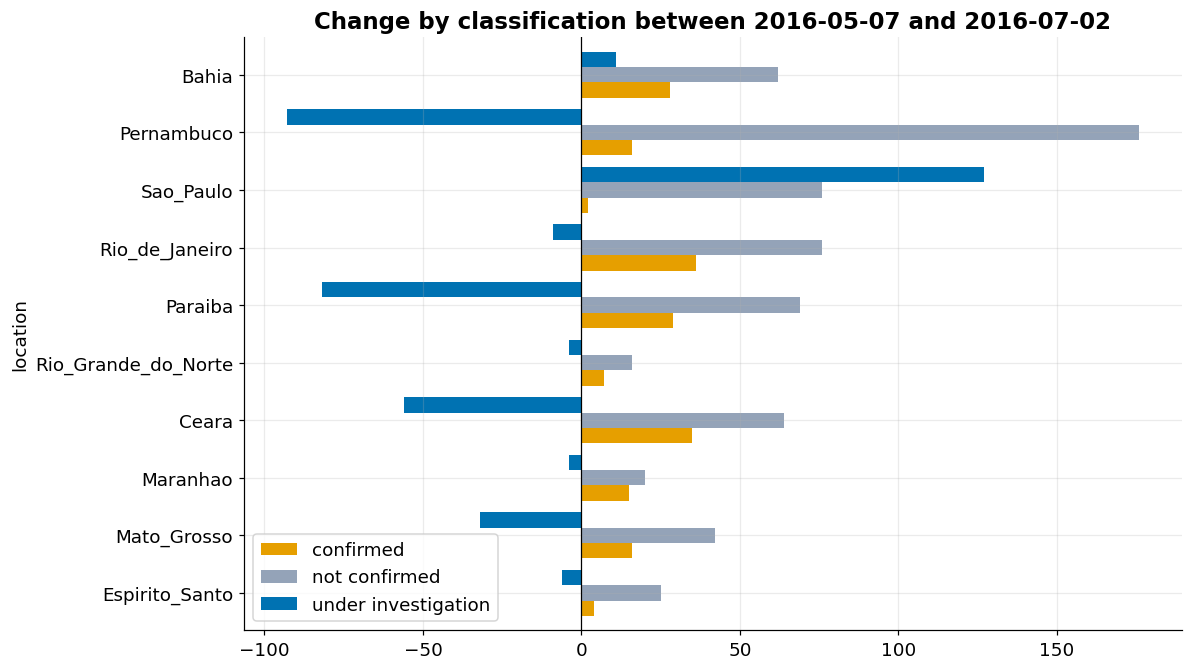

In [55]:
# change by classification for the top 10 states
top_delta = delta.loc[queue.nlargest(10, "latest").index, ["confirmed", "not confirmed", "under investigation"]].iloc[::-1]
ax = top_delta.plot.barh(figsize=(11, 7), color=[COLOR_HIGHLIGHT, COLOR_SECONDARY, COLOR_PRIMARY], width=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Change by classification between {d0:%Y-%m-%d} and {d1:%Y-%m-%d}")
plt.show()

**Result:** a stable queue does not mean a stalled state. Bahia classified 90
cases in two months and Rio de Janeiro 112, but the queue of both did not go down
because about 100 new notifications came in for each. Pernambuco reduced its queue
by 93 cases because it classified 192, almost double the 99 new notifications, but
176 of those 192 (92%) were discarded and only 16 confirmed. Paraíba, Ceará and
Mato Grosso also reduced their queues, with 65% to 72% discarded, close to the 68%
of the cumulative total. São Paulo is the extreme case: about 205 new notifications
(the most among the 10 states) against 78 classified cases, of which 76 were
discarded. Rio Grande do Norte is the only state with a large queue and very
little classification: 23 cases in two months for a queue of 261.

**Conclusion: where should the agency concentrate its effort?**

The Brazilian dataset covers 21 weekly reports (February to July 2016) and has
little Zika case data, so the forecasting in the business problem does not hold up
here. What the dataset answers well is where the microcephaly investigation is
stuck, and the states fall into four profiles:

- **Growing queue (São Paulo):** more notifications come in than the team
  classifies, and almost everything is discarded. It calls for triage capacity,
  not an outbreak response.
- **Large, stable queue with many confirmed cases (Bahia):** 659 pending and 265
  confirmed, with the queue not shrinking. This is the state where reinforcing the
  investigation is most likely to result in confirmed cases.
- **Large, stalled queue (Rio Grande do Norte):** 261 pending, 63% of the cases
  already resolved were confirmed, and almost nothing was classified in two
  months.
- **Large outbreak with the queue under control (Pernambuco, Paraíba, Ceará):**
  they concentrate confirmed cases. The priority is to follow up on the children
  already confirmed, not the queue.

Limitations: the conclusions describe the situation in July 2016 and do not
measure causes. The dataset does not separate a new notification from a
reclassification.

In [56]:
# derived metrics per state
delta["new_notifications"] = delta["confirmed"] + delta["not confirmed"] + delta["under investigation"]
delta["discard_share"] = delta["not confirmed"] / delta["resolved"]
delta["resolved_vs_queue"] = delta["resolved"] / queue["latest"]
delta.loc[queue.nlargest(10, "latest").index].round(2)

,confirmed,not confirmed,under investigation,resolved,new_notifications,discard_share,resolved_vs_queue
location,,,,,,,
Bahia,28.0,62.0,11.0,90.0,101.0,0.69,0.14
Pernambuco,16.0,176.0,-93.0,192.0,99.0,0.92,0.39
Sao_Paulo,2.0,76.0,127.0,78.0,205.0,0.97,0.27
Rio_de_Janeiro,36.0,76.0,-9.0,112.0,103.0,0.68,0.39
Paraiba,29.0,69.0,-82.0,98.0,16.0,0.70,0.37
Rio_Grande_do_Norte,7.0,16.0,-4.0,23.0,19.0,0.70,0.09
Ceara,35.0,64.0,-56.0,99.0,43.0,0.65,0.57
Maranhao,15.0,20.0,-4.0,35.0,31.0,0.57,0.39
Mato_Grosso,16.0,42.0,-32.0,58.0,26.0,0.72,0.65


In [57]:
# states outside the top 10 with the largest queue reduction
delta.loc[["Sergipe", "Tocantins", "Goias"]].round(2)

,confirmed,not confirmed,under investigation,resolved,new_notifications,discard_share,resolved_vs_queue
location,,,,,,,
Sergipe,81.0,12.0,-82.0,93.0,11.0,0.13,1.26
Tocantins,12.0,67.0,-51.0,79.0,28.0,0.85,1.34
Goias,0.0,30.0,-16.0,30.0,14.0,1.00,0.60


**Result:** the classification pace separates the states. Bahia and Rio Grande do
Norte are the ones that make the least progress on the queue: in two months they
classified 14% and 9% of the cases that are still pending, versus 57% to 65% in
Ceará and Mato Grosso. In Paraíba the queue fell mainly because almost no new
notifications are coming in (about 16 versus 98 classified), which points to an
outbreak in retreat and not to an exceptional investigation effort. Outside the
top 10, Sergipe and Tocantins classified more cases than the queue they still
have today, but with opposite profiles: Sergipe confirmed 87% of what it
resolved, Tocantins discarded 85%. A shrinking queue, therefore, does not say
what was decided.

**Conclusion: where should the agency concentrate its effort?**
The Brazilian dataset covers 21 weekly reports (February to July 2016) and has
little Zika case data, so the forecasting in the business problem does not hold up
here. What it answers well is where the microcephaly investigation is stuck. The
states fall into five profiles:

- **Growing queue (São Paulo):** about 205 notifications came in over two months
  against 78 classified, and almost everything is discarded. It calls for triage
  capacity, not an outbreak response.
- **Large, stable queue with many confirmed cases (Bahia):** 659 pending, 265
  confirmed and only 14% of the queue classified in two months. This is where
  reinforcing the investigation is most likely to yield confirmed cases.
- **Large, stalled queue (Rio Grande do Norte):** 261 pending, 63% of the cases
  already resolved were confirmed, and only 23 were classified in two months.
- **Large outbreak with the queue under control (Pernambuco, Paraíba, Ceará):**
  they concentrate confirmed cases and are classifying well. The priority is to
  follow up on the children already confirmed, not the queue.
- **Queue almost resolved (Sergipe, Tocantins):** they classified more than the
  queue they have left. They serve as a pace reference, not as an outcome: one
  confirmed almost everything, the other discarded almost everything.

Limitations: the conclusions describe the situation in July 2016 and do not
measure causes. The dataset does not separate a new notification from a
reclassification.

In [58]:
# sergipe confirmed cases: weekly change
sergipe = micro[(micro["location"] == "Brazil-Sergipe") & (micro["data_field"] == "microcephaly_confirmed")]
sergipe.set_index("report_date")["value"].diff().tail(9).to_frame("new confirmed")

,new confirmed
report_date,
2016-05-07,-4.0
2016-05-14,17.0
2016-05-21,0.0
2016-05-28,27.0
2016-06-04,33.0
2016-06-11,0.0
2016-06-18,1.0
2016-06-25,0.0
2016-07-02,3.0


In [59]:
# ranking table for all states
rk = states[["confirmed", "not confirmed", "under investigation"]].join(delta[["resolved", "new_notifications"]])
rk = rk.rename(columns={"under investigation": "pending"})
rk["confirmed_share"] = rk["confirmed"] / (rk["confirmed"] + rk["not confirmed"])
rk["pace"] = rk["resolved"] / rk["pending"]

# drop states with too few resolved cases
rk = rk[(rk["confirmed"] + rk["not confirmed"]) >= 50]
print(len(rk), "states kept of", len(states))

17 states kept of 27


In [60]:
# equal-weight score from percentile ranks
score = pd.DataFrame({
    "queue size": rk["pending"].rank(pct=True),
    "slow pace": (-rk["pace"]).rank(pct=True),
    "confirmation rate": rk["confirmed_share"].rank(pct=True),
})
rk["score"] = score.mean(axis=1)
rk.nlargest(10, "score")[["pending", "pace", "confirmed_share", "score"]].round(2)

,pending,pace,confirmed_share,score
location,,,,
Bahia,659.0,0.14,0.51,0.88
Rio_Grande_do_Norte,261.0,0.09,0.63,0.84
Rio_de_Janeiro,286.0,0.39,0.33,0.71
Maranhao,89.0,0.39,0.68,0.70
Pernambuco,489.0,0.39,0.24,0.69
Paraiba,262.0,0.37,0.24,0.65
Ceara,175.0,0.57,0.36,0.61
Sao_Paulo,290.0,0.27,0.05,0.61
Espirito_Santo,85.0,0.34,0.19,0.53


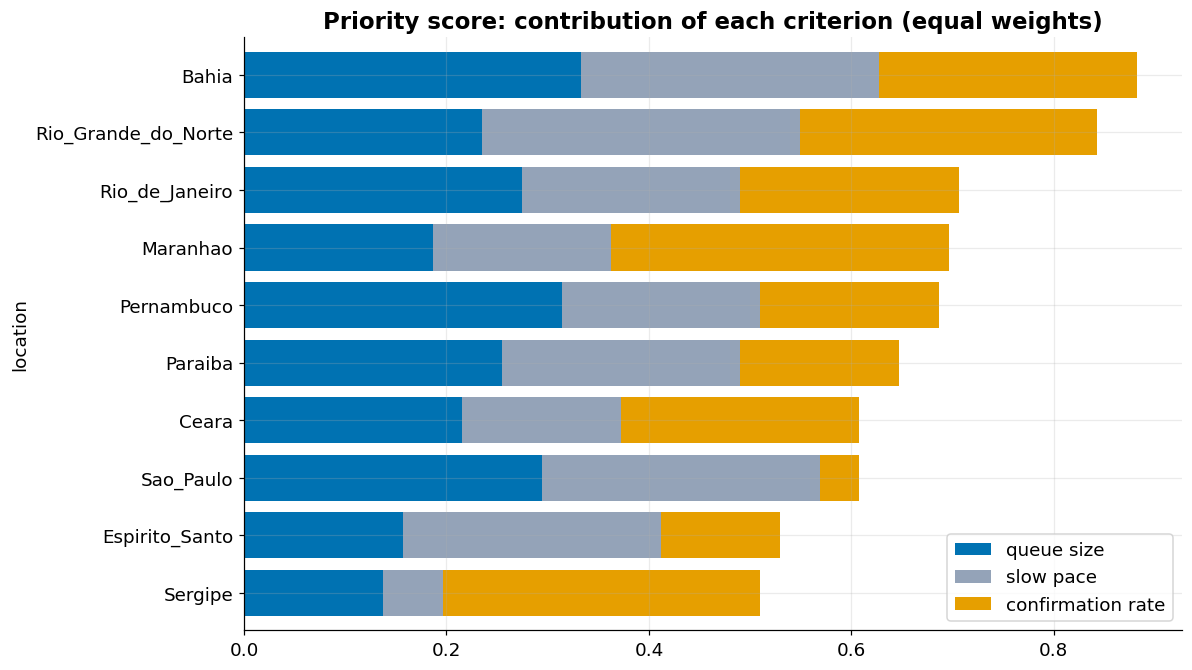

In [61]:
# contribution of each criterion to the top 10
top = score.loc[rk.nlargest(10, "score").index].iloc[::-1] / 3
ax = top.plot.barh(stacked=True, figsize=(11, 7), color=[COLOR_PRIMARY, COLOR_SECONDARY, COLOR_HIGHLIGHT], width=0.8)
ax.set_title("Priority score: contribution of each criterion (equal weights)")
plt.show()

**Result:** the ranking puts Bahia (0.88) and Rio Grande do Norte (0.84) ahead of
the rest. Bahia leads because it has the largest queue among the 17 states
evaluated, with the other two criteria also high. Rio Grande do Norte leads because
of its slowness in classifying cases and its high share of confirmed cases (63%),
even though its queue (261) is much smaller than Bahia's. Rio de Janeiro, Maranhão
and Pernambuco come next, with close scores (0.69 to 0.71), so the order among them
is fragile. The ranking measures where the investigation is most stuck and most
likely to yield confirmations. It does not measure the size of the outbreak, nor the
growth of the queue.

- **Queue almost resolved (Sergipe, Tocantins):** they classified more than the
  queue they have left. Sergipe confirmed 87% of what it resolved, but almost all of
  it in three reports in May and June, which points to a one-off revision and not to
  a pace. Tocantins discarded 85% and has not yet been checked for batch entries.
  Neither of the two serves as a pace reference before that check.

Investigation priority (ranking with equal weights across queue size, slowness and
share of confirmed cases): Bahia and Rio Grande do Norte at the top, followed by
Rio de Janeiro, Maranhão and Pernambuco, with close scores. The ranking does not
capture the size of the outbreak (Pernambuco) nor the growth of the queue
(São Paulo).

In [62]:
# states dropped by the 50-case filter, with their queue
excluded = states.drop(rk.index)
excluded[["under investigation", "total"]].sort_values("under investigation", ascending=False).head(10)

,under investigation,total
location,,
Para,45.0,46.0
Amazonas,12.0,25.0
Acre,11.0,40.0
Roraima,5.0,26.0
Rondonia,5.0,17.0
Mato_Grosso_do_Sul,3.0,22.0
Parana,2.0,37.0
Distrito_Federal,2.0,47.0
Santa_Catarina,2.0,8.0


In [63]:
# random weights, 1000 draws
rng = np.random.default_rng(42)
weights = rng.dirichlet([1, 1, 1], size=1000)
top3_per_draw = [(score * p).sum(axis=1).nlargest(3).index.tolist() for p in weights]
freq = pd.Series([e for t in top3_per_draw for e in t]).value_counts() / len(top3_per_draw)
freq.head(8).to_frame("share of draws in top 3")

,share of draws in top 3
Bahia,0.948
Rio_Grande_do_Norte,0.894
Maranhao,0.429
Pernambuco,0.246
Sao_Paulo,0.210
Rio_de_Janeiro,0.120
Minas_Gerais,0.101
Sergipe,0.052


**Result:** the cutoff of 50 resolved cases is safe: the excluded state with the
largest queue (Pará) has only 45 pending cases, versus 85 to 659 in the top 10 of
the ranking. Across the 1,000 weight draws, Bahia ranked in the top three in 95%
and Rio Grande do Norte in 89%. In other words, these two positions hold up
regardless of how the agency weighs the criteria. The third place does not hold
up: Maranhão appears in 43% of the draws, Pernambuco in 25%, São Paulo in 21%
and Rio de Janeiro in 12%. Rio de Janeiro, which held third place with equal
weights, is actually the least stable of the group.

**Conclusion: where should the agency concentrate its effort?**

The Brazilian dataset covers 27 states over 21 weekly reports (February to July
2016) and has little Zika case data (7 dates). The forecasting in the business
problem does not hold up here, and the analysis answers where the microcephaly
investigation is stuck.

**National view.** Notifications rose from about 5,300 to 8,300. The queue of cases
under investigation fell from about 3 in every 4 to 1 in every 3 (3,130 of
8,301). Among the cases already resolved, 68% were discarded (3,515 versus 1,656
confirmed). Ten states concentrate 86% of the queue.

**Priority.** Bahia and Rio Grande do Norte rank in the top three in 95% and
89% of the weight combinations tested, so they are the most robust answer:
- Bahia: largest queue (659), many confirmed cases (265) and only 14% of the queue
  classified in two months.
- Rio Grande do Norte: 261 pending, 63% confirmation among the resolved cases
  and only 23 cases classified in two months.
The third place depends on the weights: Maranhão (43% of the draws), Pernambuco
(25%), São Paulo (21%) and Rio de Janeiro (12%).

**Other profiles the ranking does not capture:**
- São Paulo: the queue grew from 163 to 290 cases, with about 205 new notifications
  against 78 classified, almost all discarded. It is a triage problem.
- Pernambuco, Paraíba and Ceará: they concentrate confirmed cases and are
  classifying well. The priority is to follow up on the children already
  confirmed, not the queue.
- Sergipe: it reduced its queue by confirming cases, but in three reports in May
  and June. It looks like a one-off revision, not a replicable pace.

**Limitations.** The data describe July 2016 and do not measure causes. The dataset
does not separate a new notification from a reclassification, and the priority
score depends on equal weights, which are an assumption, not an agency rule.

In [64]:
# tocantins not confirmed: weekly change
tocantins = micro[(micro["location"] == "Brazil-Tocantins") & (micro["data_field"] == "microcephaly_not")]
tocantins.set_index("report_date")["value"].diff().tail(9).to_frame("new not confirmed")

,new not confirmed
report_date,
2016-05-07,4.0
2016-05-14,7.0
2016-05-21,5.0
2016-05-28,0.0
2016-06-04,48.0
2016-06-11,-1.0
2016-06-18,5.0
2016-06-25,3.0
2016-07-02,0.0


In [65]:
# minas gerais row in the ranking table
rk.loc[["Minas_Gerais"], ["pending", "pace", "confirmed_share", "score"]].round(2)

,pending,pace,confirmed_share,score
location,,,,
Minas_Gerais,64.0,0.0,0.05,0.45


**Result:** Tocantins was also a batch. Of the 67 cases discarded in the window, 48
(72%) came in the June 4 report, and the other seven reports add up to 19. Sergipe
and Tocantins reduced their queues in the same way, with a one-off revision, and one
ended up confirming and the other discarding. Minas Gerais appears in the top 3 in
10% of the draws for a different reason than I had assumed: its share of confirmed
cases is low (5%) and its queue is small (64 cases). What takes it to the top is
slowness, since it did not classify any case in two months.

- Sergipe and Tocantins: they reduced their queues through one-off revisions.
  Sergipe confirmed 77 cases in three reports in May and June, and Tocantins
  discarded 48 in a single report, on June 4. Neither serves as a pace reference,
  and the drop in their queues should not be read as continuous improvement.
- Minas Gerais: small queue (64 cases), but no case classified in two months.
  It appears in the top 3 only when slowness dominates the weight, so it stays as
  a point of attention and not as a priority.

In [66]:
# last report date per state
micro.groupby("location")["report_date"].max().sort_values().head(8).to_frame("last report")

,last report
location,
Brazil-Acre,2016-07-02
Brazil-Sao_Paulo,2016-07-02
Brazil-Santa_Catarina,2016-07-02
Brazil-Roraima,2016-07-02
Brazil-Rondonia,2016-07-02
Brazil-Rio_de_Janeiro,2016-07-02
Brazil-Rio_Grande_do_Sul,2016-07-02
Brazil-Rio_Grande_do_Norte,2016-07-02


**Result:** all states reported up to July 2, 2016, the final date in the dataset.
Therefore the zero pace of Minas Gerais does not come from missing data: the state
sent reports throughout the entire window, and its queue of 64 pending cases simply
was not classified in two months.

- Minas Gerais: small queue (64 cases), no case classified in two months, even
  though the state reported on every date. It appears in the top 3 only when
  slowness dominates the weight, so it stays as a point of attention and not as a
  priority.